In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, ShuffleSplit, cross_val_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb

# 1. Load Data
df1=pd.read_csv('/Bengaluru_House_Data.csv')

# 2. Data Cleaning & Feature Engineering
df2 = df1.drop(['area_type', 'availability', 'society'], axis='columns')
df3 = df2.dropna().copy()

df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0]))

def convert_sqft_to_num(x):
    tokens = str(x).split('-')
    if len(tokens) == 2:
        return (float(tokens[0]) + float(tokens[1])) / 2
    try:
        return float(x)
    except:
        return None

df4 = df3.copy()
df4['total_sqft'] = df4['total_sqft'].apply(convert_sqft_to_num)
df4 = df4.dropna()

df5 = df4.copy()
df5['price_per_sqft'] = df5['price'] * 100000 / df5['total_sqft']

# Dimensionality Reduction for Location
df5.location = df5.location.apply(lambda x: x.strip())
location_stats = df5.groupby('location')['location'].agg('count').sort_values(ascending=False)
location_stats_less_than_10 = location_stats[location_stats <= 10]
df5.location = df5.location.apply(lambda x: 'other' if x in location_stats_less_than_10 else x)

# 3. Outlier Removal
# Outlier Removal using SQFT per BHK threshold
df6 = df5[~(df5.total_sqft / df5.bhk < 300)]

# Outlier Removal using Mean and Standard Deviation per Location
def remove_pps_outliers(df):
    df_out = pd.DataFrame()
    for key, subdf in df.groupby('location'):
        m = np.mean(subdf.price_per_sqft)
        st = np.std(subdf.price_per_sqft)
        reduced_df = subdf[(subdf.price_per_sqft > (m - st)) & (subdf.price_per_sqft <= (m + st))]
        df_out = pd.concat([df_out, reduced_df], ignore_index=True)
    return df_out

df7 = remove_pps_outliers(df6)

# Outlier Removal for BHK anomalies (where 2 BHK price_per_sqft > 3 BHK price_per_sqft in same location)
def remove_bhk_outliers(df):
    exclude_indices = np.array([])
    for location, location_df in df.groupby('location'):
        bhk_stats = {}
        for bhk, bhk_df in location_df.groupby('bhk'):
            bhk_stats[bhk] = {
                'mean': np.mean(bhk_df.price_per_sqft),
                'std': np.std(bhk_df.price_per_sqft),
                'count': bhk_df.shape[0]
            }
        for bhk, bhk_df in location_df.groupby('bhk'):
            stats = bhk_stats.get(bhk - 1)
            if stats and stats['count'] > 5:
                exclude_indices = np.append(exclude_indices, bhk_df[bhk_df.price_per_sqft < (stats['mean'])].index.values)
    return df.drop(exclude_indices, axis='index')

df8 = remove_bhk_outliers(df7)

# Outlier Removal for Bathroom Feature
df9 = df8[df8.bath < df8.bhk + 2]

# Prepare Data for Machine Learning
df10 = df9.drop(['size', 'price_per_sqft'], axis='columns')

# One-Hot Encoding for Location
dummies = pd.get_dummies(df10.location, drop_first=True)
df11 = pd.concat([df10.drop('location', axis='columns'), dummies], axis='columns')

X = df11.drop('price', axis='columns')
y = df11.price

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

# 5. Model Selection & Hyperparameter Tuning using GridSearchCV
def find_best_model_using_gridsearchcv(X, y):
    algos = {
        'linear_regression': {
            'model': LinearRegression(),
            'params': {}
        },
        'lasso': {
            'model': Lasso(),
            'params': {
                'alpha': [1, 2],
                'selection': ['random', 'cyclic']
            }
        },
        'decision_tree': {
            'model': DecisionTreeRegressor(),
            'params': {
                'criterion': ['squared_error', 'friedman_mse'],
                'splitter': ['best', 'random']
            }
        },
        'random_forest': {
            'model': RandomForestRegressor(),
            'params': {
                'n_estimators': [100, 200],
                'max_depth': [10, 20, None]
            }
        },
        'xgboost': {
            'model': xgb.XGBRegressor(),
            'params': {
                'n_estimators': [100, 200],
                'learning_rate': [0.05, 0.1],
                'max_depth': [3, 5, 7]
            }
        }
    }

    scores = []
    cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)
    for algo_name, config in algos.items():
        gs = GridSearchCV(config['model'], config['params'], cv=cv, return_train_score=False)
        gs.fit(X, y)
        scores.append({
            'model': algo_name,
            'best_score': gs.best_score_,
            'best_params': gs.best_params_
        })

    return pd.DataFrame(scores, columns=['model', 'best_score', 'best_params'])

# Run GridSearchCV across models
model_performance = find_best_model_using_gridsearchcv(X, y)
print("Model Comparison Summary:")
print(model_performance)

# 6. Fit the Best Model (XGBoost Regressor)
best_model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42)
best_model.fit(X_train, y_train)

# Evaluation
train_score = best_model.score(X_train, y_train)
test_score = best_model.score(X_test, y_test)
print(f"\nBest Model Train R^2 Score: {train_score:.4f}")
print(f"Best Model Test R^2 Score: {test_score:.4f}")

# 7. Helper Function for Price Prediction
def predict_price(location, sqft, bath, bhk, balcony):
    loc_index = np.where(X.columns == location)[0][0] if location in X.columns else -1

    x = np.zeros(len(X.columns))
    x[0] = sqft
    x[1] = bath
    x[2] = balcony
    x[3] = bhk
    if loc_index >= 0:
        x[loc_index] = 1

    return best_model.predict([x])[0]

# Sample Prediction Test
sample_pred = predict_price('1st Phase JP Nagar', 1000, 2, 2, 1)
print(f"\nSample Prediction for 1st Phase JP Nagar (1000 sqft, 2 BHK, 2 Bath, 1 Balcony): {sample_pred:.2f} Lakhs")
print("Cell finished running successfully!")

Model Comparison Summary:
               model  best_score  \
0  linear_regression    0.841557   
1              lasso    0.693488   
2      decision_tree    0.723425   
3      random_forest    0.792992   
4            xgboost    0.835920   

                                         best_params  
0                                                 {}  
1                {'alpha': 1, 'selection': 'random'}  
2  {'criterion': 'squared_error', 'splitter': 'ra...  
3           {'max_depth': None, 'n_estimators': 100}  
4  {'learning_rate': 0.1, 'max_depth': 5, 'n_esti...  

Best Model Train R^2 Score: 0.9172
Best Model Test R^2 Score: 0.8753

Sample Prediction for 1st Phase JP Nagar (1000 sqft, 2 BHK, 2 Bath, 1 Balcony): 63.54 Lakhs
Cell finished running successfully!


# New Section

Mean Absolute Error (MAE): 16.05 Lakhs
Root Mean Squared Error (RMSE): 25.32 Lakhs
R^2 Score: 0.8753

First 10 Sample Predictions:


,Actual Price (Lakhs),Predicted Price (Lakhs),Difference (Lakhs)
0,36.85,36.443039,0.406961
1,325.00,264.883362,60.116638
2,66.00,58.955872,7.044128
3,44.00,47.015438,-3.015438
4,62.00,51.648396,10.351604
5,71.00,76.929832,-5.929832
6,120.00,121.405418,-1.405418
7,41.13,58.955872,-17.825872
8,88.00,68.056038,19.943962
9,110.00,126.390381,-16.390381


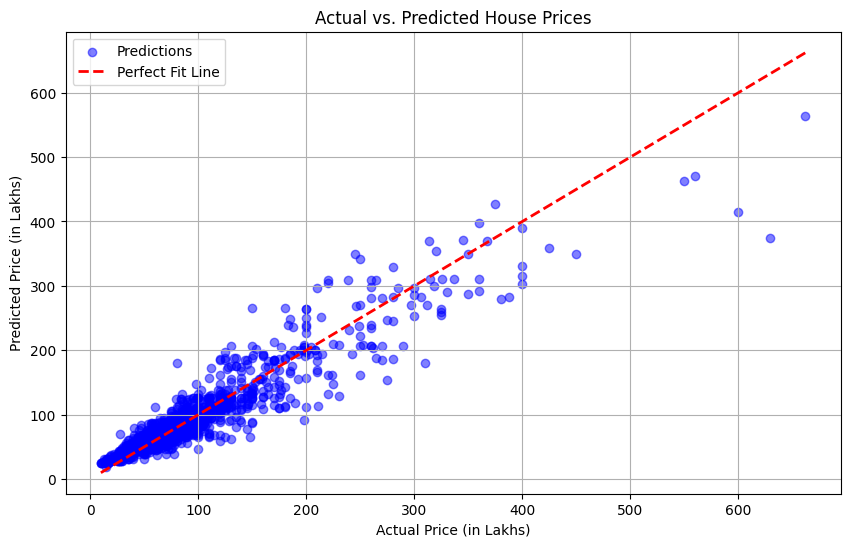

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. Generate predictions on the test set
y_pred = best_model.predict(X_test)

# 2. Calculate Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f} Lakhs")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} Lakhs")
print(f"R^2 Score: {r2:.4f}")

# 3. Create Actual vs. Predicted Comparison DataFrame
comparison_df = pd.DataFrame({
    'Actual Price (Lakhs)': y_test.values,
    'Predicted Price (Lakhs)': y_pred,
    'Difference (Lakhs)': y_test.values - y_pred
})

print("\nFirst 10 Sample Predictions:")
display(comparison_df.head(10))

# 4. Plot Actual vs. Predicted Prices
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue', label='Predictions')

# Ideal diagonal line (where Actual == Predicted)
max_val = max(y_test.max(), y_pred.max())
min_val = min(y_test.min(), y_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit Line')

plt.xlabel('Actual Price (in Lakhs)')
plt.ylabel('Predicted Price (in Lakhs)')
plt.title('Actual vs. Predicted House Prices')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Round numerical columns to 2 decimal places
comparison_df_clean = comparison_df.round(2)

print("\nFirst 10 Sample Predictions (Formatted):")
display(comparison_df_clean.head(10))


First 10 Sample Predictions (Formatted):


,Actual Price (Lakhs),Predicted Price (Lakhs),Difference (Lakhs)
0,36.85,36.439999,0.41
1,325.00,264.880005,60.12
2,66.00,58.959999,7.04
3,44.00,47.020000,-3.02
4,62.00,51.650002,10.35
5,71.00,76.930000,-5.93
6,120.00,121.410004,-1.41
7,41.13,58.959999,-17.83
8,88.00,68.059998,19.94
9,110.00,126.389999,-16.39


In [ ]:
import pandas as pd

# 1. Define custom test data
test_data = [
    {'location': 'Whitefield', 'total_sqft': 1170, 'bath': 2, 'balcony': 1, 'bhk': 2, 'actual_price': 52.0},
    {'location': 'Electronic City', 'total_sqft': 1500, 'bath': 3, 'balcony': 2, 'bhk': 3, 'actual_price': 72.5},
    {'location': 'Rajaji Nagar', 'total_sqft': 1200, 'bath': 2, 'balcony': 1, 'bhk': 2, 'actual_price': 145.0},
    {'location': 'Indiranagar', 'total_sqft': 2400, 'bath': 4, 'balcony': 3, 'bhk': 4, 'actual_price': 320.0},
    {'location': 'Sarjapur Road', 'total_sqft': 650, 'bath': 1, 'balcony': 1, 'bhk': 1, 'actual_price': 30.0},
    {'location': '1st Phase JP Nagar', 'total_sqft': 1875, 'bath': 3, 'balcony': 1, 'bhk': 3, 'actual_price': 167.0},
    {'location': 'Hebbal', 'total_sqft': 1600, 'bath': 2, 'balcony': 2, 'bhk': 3, 'actual_price': 95.0},
    {'location': 'Yelahanka', 'total_sqft': 1320, 'bath': 2, 'balcony': 2, 'bhk': 2, 'actual_price': 58.0},
    {'location': 'Koramangala', 'total_sqft': 2100, 'bath': 3, 'balcony': 2, 'bhk': 3, 'actual_price': 240.0},
    {'location': 'Marathahalli', 'total_sqft': 1100, 'bath': 2, 'balcony': 1, 'bhk': 2, 'actual_price': 65.0}
]

# 2. Predict prices using your function
results = []
for sample in test_data:
    pred = predict_price(sample['location'], sample['total_sqft'], sample['bath'], sample['bhk'], sample['balcony'])
    results.append({
        'Location': sample['location'],
        'BHK': sample['bhk'],
        'Sqft': sample['total_sqft'],
        'Actual Price (Lakhs)': sample['actual_price'],
        'Predicted Price (Lakhs)': round(pred, 2),
        'Difference (Lakhs)': round(sample['actual_price'] - pred, 2)
    })

# 3. Display as DataFrame
test_results_df = pd.DataFrame(results)
display(test_results_df)

,Location,BHK,Sqft,Actual Price (Lakhs),Predicted Price (Lakhs),Difference (Lakhs)
0,Whitefield,2,1170,52.0,60.299999,-8.300000
1,Electronic City,3,1500,72.5,87.320000,-14.820000
2,Rajaji Nagar,2,1200,145.0,171.949997,-26.950001
3,Indiranagar,4,2400,320.0,185.669998,134.330002
4,Sarjapur Road,1,650,30.0,34.410000,-4.410000
5,1st Phase JP Nagar,3,1875,167.0,155.580002,11.420000
6,Hebbal,3,1600,95.0,108.540001,-13.540000
7,Yelahanka,2,1320,58.0,71.139999,-13.140000
8,Koramangala,3,2100,240.0,235.860001,4.140000
9,Marathahalli,2,1100,65.0,52.930000,12.070000


In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split, GridSearchCV, ShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# 1. PREPARE DATA & APPLY LOG TRANSFORMATION
# ==========================================

# X and y from your preprocessed dataframe (df11)
X = df11.drop('price', axis='columns')
y = df11.price

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

# Log Transformation on target variable (y) to fix skewness
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# ==========================================
# 2. HYPERPARAMETER TUNING USING GRIDSEARCHCV
# ==========================================

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],            # Depth of trees
    'learning_rate': [0.03, 0.05, 0.1], # Step size shrinkage
    'subsample': [0.7, 0.8, 1.0],      # Row sampling ratio
    'colsample_bytree': [0.7, 0.8, 1.0] # Column sampling ratio
}

# Base XGBoost Regressor
xgb_reg = xgb.XGBRegressor(random_state=42)

cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)

# Grid Search with cross-validation
grid_search = GridSearchCV(
    estimator=xgb_reg,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

# Fit model on LOG-TRANSFORMED target
grid_search.fit(X_train, y_train_log)

# Best Model
best_xgb_model = grid_search.best_estimator_

print("\n--- Best Model Parameters ---")
print(grid_search.best_params_)

# ==========================================
# 3. EVALUATION (CONVERT PREDICTIONS BACK)
# ==========================================

# Predict on log scale
y_pred_log = best_xgb_model.predict(X_test)

# Inverse Log Transformation using np.expm1
y_pred = np.expm1(y_pred_log)

# Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Optimized Model Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} Lakhs")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} Lakhs")
print(f"R^2 Score: {r2:.4f}")

# ==========================================
# 4. UPDATED PREDICTION FUNCTION
# ==========================================

def predict_price_optimized(location, sqft, bath, bhk, balcony):
    loc_index = np.where(X.columns == location)[0][0] if location in X.columns else -1

    x = np.zeros(len(X.columns))
    x[0] = sqft
    x[1] = bath
    x[2] = balcony
    x[3] = bhk
    if loc_index >= 0:
        x[loc_index] = 1

    # Predict log price
    pred_log = best_xgb_model.predict([x])[0]

    # Reverse log transform to get price in Lakhs
    return np.expm1(pred_log)

# ==========================================
# 5. TEST ON LUXURY SAMPLE (INDIRANAGAR)
# ==========================================

# Test on Indiranagar 4 BHK (Previously severely underestimated)
indirangar_pred = predict_price_optimized('Indiranagar', 2400, 4, 4, 3)
print(f"\nIndiranagar (2400 sqft, 4 BHK) - New Predicted Price: {indirangar_pred:.2f} Lakhs")

Fitting 5 folds for each of 243 candidates, totalling 1215 fits

--- Best Model Parameters ---
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.7}

--- Optimized Model Metrics ---
Mean Absolute Error (MAE): 13.21 Lakhs
Root Mean Squared Error (RMSE): 23.68 Lakhs
R^2 Score: 0.8909

Indiranagar (2400 sqft, 4 BHK) - New Predicted Price: 173.27 Lakhs


In [ ]:
import json

# 1. Save the model in XGBoost's native JSON format (prevents version mismatch errors)
best_xgb_model.save_model("model.json")

# 2. Save the feature column names
columns = {
    'data_columns': [col.lower() for col in X.columns]
}
with open("columns.json", "w") as f:
    f.write(json.dumps(columns))

print("Model saved successfully as model.json!")

Model saved successfully as model.json!
